# HPC log EDA

## Load data

In [ ]:
import re
import pandas as pd

LOG_PATH = "data/original_dataset/HPC.log"
COLUMNS = ["event_id", "node", "component", "state", "time", "flag", "message"]

LINE_RE = re.compile(r"^(\d+) (.*?) (\S+) (\S+) (\d+(?:\.\d+)?) (-?\d)(?: (.*))?$")


def load_hpc_log(path=LOG_PATH):
    with open(path, "rb") as f:
        lines = [l for l in f.read().decode("ascii").split("\r\n") if l]

    rows, unparsed = [], []
    for line in lines:
        m = LINE_RE.match(line)
        if m:
            rows.append(m.groups())
        else:
            unparsed.append(line)
    
    df = pd.DataFrame(rows, columns=COLUMNS)
    df["message"] = df["message"].fillna("")
    df["event_id"] = df["event_id"].astype("int64")
    df["flag"] = df["flag"].astype("int8")
    t = pd.to_numeric(df["time"], errors="coerce")
    df["bad_time"] = ~df["time"].str.fullmatch(r"\d{10}")
    df["ts"] = pd.to_datetime(t.where(~df["bad_time"]), unit="s")
    df["time"] = t
    df["row"] = range(len(df))
    return df, unparsed

In [2]:
df, unparsed = load_hpc_log()
print(f"{len(df):,} rows, {len(unparsed)} unparsed, {df.bad_time.sum()} bad timestamps")
df.head()

433,490 rows, 0 unparsed, 9 bad timestamps


,event_id,node,component,state,time,flag,message,bad_time,ts,row
0,460903,resourcemgmtdaeomon node-25,server,subsys,1.145552e+09,1,failed to configure resourcemgmt subsystem err...,False,2006-04-20 16:56:56,0
1,460919,resourcemgmtdaeomon node-25,server,subsys,1.145552e+09,1,failed to configure resourcemgmt subsystem err...,False,2006-04-20 16:57:01,1
2,460932,resourcemgmtdaeomon node-25,server,subsys,1.145552e+09,1,failed to configure resourcemgmt subsystem err...,False,2006-04-20 16:57:06,2
3,460949,resourcemgmtdaeomon node-25,server,subsys,1.145552e+09,1,failed to configure resourcemgmt subsystem err...,False,2006-04-20 16:57:12,3
4,460971,resourcemgmtdaeomon node-25,server,subsys,1.145552e+09,1,failed to configure resourcemgmt subsystem err...,False,2006-04-20 16:57:17,4


## Column distributions

In [3]:
for col in ["component", "state", "flag"]:
    print(df[col].value_counts())
    print(len(df[col].unique()), " unique values \n")

component
switch_module        131600
node                 113275
gige                 100190
unix.hw               30086
action                28591
clusterfilesystem     15947
partition              7542
boot_cmd               3902
domain                 1458
shutdown_cmd            398
tserver                 362
install_cmd              57
server                   50
del_member_cmd           32
Name: count, dtype: int64
14  unique values 

state
temperature                     154930
error                           105572
status                           67348
start                            27818
net.niff.up                      23121
fan                              21774
clusterfilesystem.not_served      8152
clusterfilesystem.no_server       5126
bcast-error                       3718
state_change.unavailable          2969
state_change.available            2869
fdmn.full                         2599
new                               2108
success                           1741


C:\Users\user\AppData\Local\Temp\ipykernel_3008\3419558218.py:7: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result
  mdates.date2num(plot_df.loc[plot_df["component"] == component, "ts"].dt.to_pydatetime())


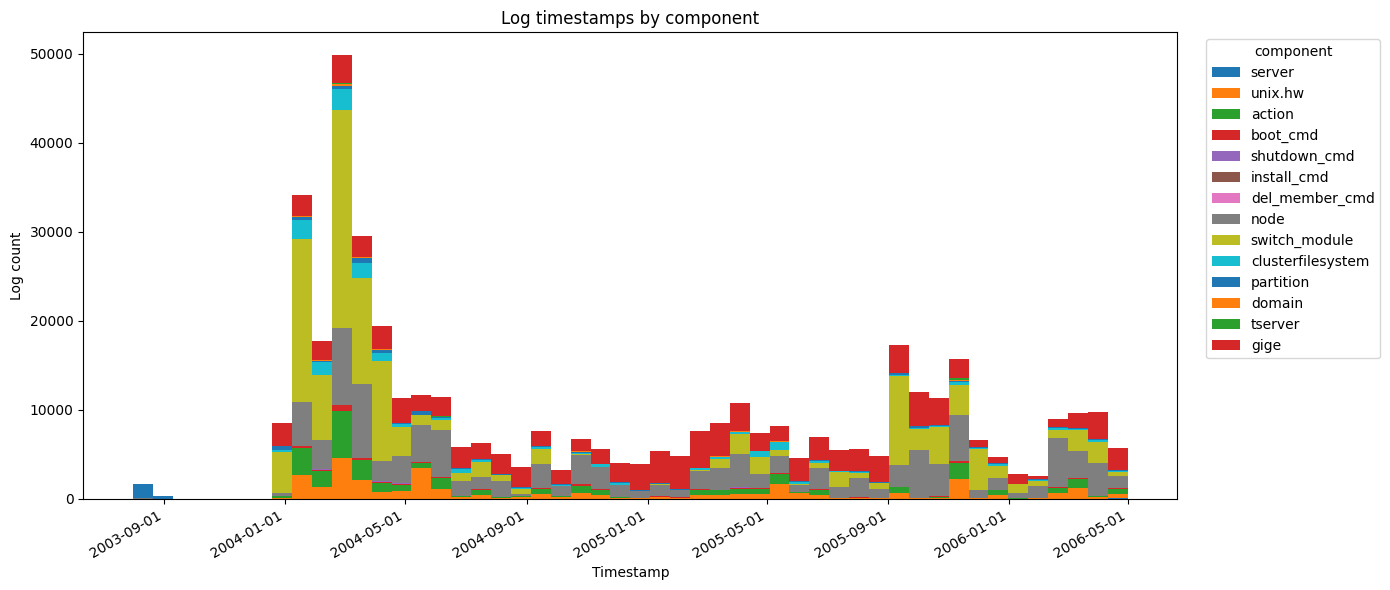

In [4]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plot_df = df.dropna(subset=["ts"])
components = plot_df["component"].unique()
times = [
    mdates.date2num(plot_df.loc[plot_df["component"] == component, "ts"].dt.to_pydatetime())
    for component in components
]

fig, ax = plt.subplots(figsize=(14, 6))
ax.hist(times, bins=50, stacked=True, label=components)
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax.set(xlabel="Timestamp", ylabel="Log count", title="Log timestamps by component")
ax.legend(title="component", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## flag by component and state
Trying to understand when the -1 and 0 flags show up

In [5]:
t = df.groupby(["component", "state", "flag"]).size().unstack("flag", fill_value=0)
t[(t[0] > 0) | (t[-1] > 0)].sort_values(by=[-1, 0, 1], ascending=False).head(10)

flag                         -1      0       1
component     state                           
partition     status       2083     36    5423
node          status       1045  11516   45425
switch_module error          34    134  104423
              control         3      0     528
node          temperature     0     73   54669
domain        status          0     20    1438

## flag over time

In [6]:
pd.crosstab(df.ts.dt.to_period("Q"), df.flag)

flag,-1,0,1
ts,,,
2003Q3,1932,0,0
2003Q4,0,0,3930
2004Q1,26,2484,135292
2004Q2,832,2981,52543
2004Q3,57,1362,23606
2004Q4,0,918,20523
2005Q1,0,154,33458
2005Q2,0,1416,29106
2005Q3,306,1028,37132


## message templates
Normalize the text to identify common error/message templates in the content of the logs.

In [7]:
def crude_template(s):
    s = re.sub(r"\\04[27].*?\\04[27]", "<Q>", s)
    s = re.sub(r"\b0x[0-9a-fA-F]+\b", "<HEX>", s)
    s = re.sub(r"\b(node|gige|Interconnect)-?[\w-]*\d\b", "<NODE>", s)
    s = re.sub(r"\d+", "<N>", s)
    return re.sub(r"\s+", " ", s).strip()


df["tmpl"] = df.message.map(crude_template)
df.groupby(["component", "state", "tmpl"]).size().sort_values(ascending=False).head(200)

component      state        tmpl                                                                                                       
switch_module  error        Linkerror event interval expired                                                                               84894
node           temperature  ambient=<N>                                                                                                    54739
gige           temperature  warning                                                                                                        49741
                            normal                                                                                                         45818
node           status       running                                                                                                        25123
                                                                                                                                           

## Size and time span

In [8]:
timed = df.dropna(subset=["ts"])
days = (timed.ts.max() - timed.ts.min()).days
print(f"{len(df):,} lines from {timed.ts.min()} to {timed.ts.max()}")
print(f"{days:,} days, about {days / 30.44:.0f} months")

433,490 lines from 2003-07-31 11:04:04 to 2006-04-30 11:28:24
1,004 days, about 33 months


## Distinct events after dropping identical copies

In [9]:
COPY_KEY = ["node", "component", "state", "time", "message"]
events = df.drop_duplicates(COPY_KEY).copy()
print(f"{len(events):,} distinct events, {len(df) - len(events):,} copies dropped")

411,483 distinct events, 22,007 copies dropped


## Does event_id identify an event?

In [10]:
events_per_id = events.groupby("event_id").size()
print(f"{len(events_per_id):,} distinct event_id values over {len(events):,} distinct events")
print(f"{(events_per_id > 1).sum():,} event_id values appear on more than one distinct event")

325,352 distinct event_id values over 411,483 distinct events
78,572 event_id values appear on more than one distinct event


## event_id range per quarter, and how far apart events that share one are

In [11]:
timed_events = events.dropna(subset=["ts"])
shared = timed_events[timed_events.groupby("event_id").event_id.transform("size") > 1]
by_id = shared.groupby("event_id").ts
days_apart = (by_id.max() - by_id.min()).dt.days
print(f"{len(days_apart):,} event_id values sit on more than one event with a usable timestamp")
print(f"two events that share an event_id are at least {days_apart.min()} days apart, median {days_apart.median():.0f}")
events.groupby(events.ts.dt.to_period("Q")).event_id.agg(["min", "max"])

78,568 event_id values sit on more than one event with a usable timestamp
two events that share an event_id are at least 18 days apart, median 532


,min,max
ts,,
2003Q3,2253146,2313342
2003Q4,2550225,2557090
2004Q1,0,2616649
2004Q2,289152,394227
2004Q3,394228,436655
2004Q4,17972,457836
2005Q1,39372,140624
2005Q2,140625,277596
2005Q3,1,327484


## Kinds of values in the node field

In [12]:
# the node value with every number replaced by N, e.g. node-25 -> node-N
node_kind = events.node.str.replace(r"\d+", "N", regex=True)
by_kind = events.groupby(node_kind)
pd.DataFrame({
    "events": by_kind.size(),
    "distinct_values": by_kind.node.nunique(),
    "example": by_kind.node.first(),
    "components": by_kind.component.agg(lambda c: ", ".join(sorted(set(c)))),
}).sort_values("events", ascending=False)

,events,distinct_values,example,components
node,,,,
node-N,158466,256,node-233,"action, node, unix.hw"
Interconnect-NNN,103383,8,Interconnect-0N00,switch_module
gigeN,98809,8,gige2,gige
Interconnect-NTN,23192,8,Interconnect-0T00,switch_module
node-DN,16907,8,node-D0,"action, clusterfilesystem, domain"
full,5850,1,full,partition
N,4302,2078,1894,"boot_cmd, del_member_cmd, install_cmd, shutdow..."
node--tcN,362,8,node--tc2,tserver
node-msN,120,1,node-ms0,"node, unix.hw"


## Events whose node field has two words

In [13]:
two_words = events[events.node.str.contains(" ")]
print(f"{len(two_words)} events from {two_words.ts.min()} to {two_words.ts.max()}")
two_words.groupby(["node", "component", "state", "message"]).size().rename("events").reset_index()

50 events from 2006-04-20 16:56:56 to 2006-04-20 17:36:08


,node,component,state,message,events
0,resourcemgmtdaeomon node-25,server,subsys,failed to configure resourcemgmt subsystem err...,28
1,resourcemgmtdaeomon node-31,server,subsys,failed to configure resourcemgmt subsystem err...,22


## Messages that contain "An ServerFileSystem"

In [14]:
events[events.message.str.contains("An ServerFileSystem")].tmpl.value_counts()

tmpl
ServerFileSystem: An ServerFileSystem domain panic has occurred on storage<N>       69
ServerFileSystem: An ServerFileSystem domain panic has occurred on root<N>_local     1
Name: count, dtype: int64

## Events per day

In [15]:
per_day = events.groupby(events.ts.dt.date).size()
print(f"{len(per_day):,} days with logs out of {days + 1:,}")
print(f"median {per_day.median():.0f} events on a day with logs, busiest {per_day.max():,} on {per_day.idxmax()}")

809 days with logs out of 1,005
median 236 events on a day with logs, busiest 12,942 on 2004-02-27


## Template keys: component, state and masked message

In [16]:
TEMPLATE_KEY = ["component", "state", "tmpl"]
keys = events[TEMPLATE_KEY].drop_duplicates().reset_index(drop=True)
print(f"{len(keys)} template keys, {keys.tmpl.nunique()} distinct masked messages")

249 template keys, 201 distinct masked messages


## Template keys that differ only in the length of a list

In [17]:
LIST_FAMILIES = ["Targeting domains", "inconsistent nodesets", "Command Failed on", "Failed subcommands"]


def list_family(tmpl):
    for family in LIST_FAMILIES:
        if tmpl.startswith(family):
            # the Targeting message has a second form that names a parent command
            return family + (" (child of command)" if "child of command" in tmpl else "")
    return None


keys["family"] = keys.tmpl.map(list_family)
in_family = keys.family.notna()
# every key of a family gets the family name as its text, so its variants fall together
collapsed = keys.assign(tmpl=keys.family.fillna(keys.tmpl))[TEMPLATE_KEY].drop_duplicates()
print(f"{in_family.sum()} of {len(keys)} template keys belong to these families")
print(f"{len(collapsed)} template keys are left when each family counts once per component and state")

family_keys = keys[in_family]
pd.DataFrame({
    "keys": family_keys.groupby("family").size(),
    "after_collapsing": family_keys.drop_duplicates(["component", "state", "family"]).groupby("family").size(),
})

123 of 249 template keys belong to these families
142 template keys are left when each family counts once per component and state


,keys,after_collapsing
family,,
Command Failed on,26,6
Failed subcommands,13,3
Targeting domains,42,4
Targeting domains (child of command),16,2
inconsistent nodesets,26,1


## Template keys first seen in each quarter

In [18]:
first_seen = events.groupby(TEMPLATE_KEY).ts.min()
first_seen.dt.to_period("Q").value_counts().sort_index().rename("new template keys")

ts
2003Q3      2
2003Q4     46
2004Q1    123
2004Q2     26
2004Q3      1
2004Q4      7
2005Q1     10
2005Q2     12
2005Q3      7
2005Q4     11
2006Q1      1
2006Q2      3
Freq: Q-DEC, Name: new template keys, dtype: int64

## Error-like events by keyword

In [19]:
ERROR_WORDS = [
    "fail", "error", "panic", "full", "critical", "exceed", "not respond", "not-respond", "unavailable",
    "no server", "no longer", "abort", "refused", "timeout", "problem", "unknown", "down", "inconsistent", "cancel",
]
RECOVERY_PHRASES = ["link ok", "power/control ok", "completed successfully"]

has_error_word = events.tmpl.str.contains("|".join(ERROR_WORDS), case=False)
is_recovery = events.tmpl.str.contains("|".join(RECOVERY_PHRASES), case=False)
errors = events[has_error_word & ~is_recovery & events.ts.notna()].copy()
print(f"{len(errors):,} of {len(events):,} events ({len(errors) / len(events):.0%}) are error-like")
print(f"they cover {len(errors[TEMPLATE_KEY].drop_duplicates())} of {len(keys)} template keys")

138,792 of 411,483 events (34%) are error-like
they cover 149 of 249 template keys


## Incidents: error-like events of one component with less than an hour between them

In [20]:
GAP_S = 3600

errors = errors.sort_values(["component", "time"], kind="stable")
# the first event of a component, or one that comes more than GAP_S after the previous, opens an incident
new_incident = errors.groupby("component").time.diff().fillna(float("inf")) > GAP_S
errors["incident"] = new_incident.cumsum()

by_incident = errors.groupby("incident")
incidents = pd.DataFrame({
    "component": by_incident.component.first(),
    "events": by_incident.size(),
    "nodes": by_incident.node.nunique(),
    "hours": (by_incident.time.max() - by_incident.time.min()) / 3600,
})
print(f"{len(incidents):,} incidents, {len(incidents) / days:.1f} per day")
incidents[["events", "nodes", "hours"]].describe(percentiles=[0.5, 0.9, 0.99]).round(1)

6,676 incidents, 6.6 per day


,events,nodes,hours
count,6676.0,6676.0,6676.0
mean,20.8,3.5,1.0
std,290.0,17.2,9.0
min,1.0,1.0,0.0
50%,2.0,1.0,0.0
90%,15.0,5.0,2.0
99%,256.0,32.2,11.5
max,13867.0,256.0,561.5


## Incident shapes: component plus the set of template keys in the incident

In [21]:
errors["key"] = errors.state + " | " + errors.tmpl
incidents["shape"] = incidents.component + ": " + errors.groupby("incident").key.agg(lambda k: " + ".join(sorted(set(k))))

shapes = incidents["shape"].value_counts()
top = shapes.head(20).sum()
print(f"{len(shapes)} distinct shapes over {len(incidents):,} incidents")
print(f"the 20 most common shapes cover {top:,} incidents ({top / len(incidents):.0%})")
shapes.head(20).rename("incidents").reset_index()

298 distinct shapes over 6,676 incidents
the 20 most common shapes cover 5,912 incidents (89%)


,shape,incidents
0,gige: temperature | critical,1773
1,switch_module: error | Linkerror event interva...,909
2,switch_module: error | link errors remain current,905
3,node: status | not responding,534
4,clusterfilesystem: fdmn.full | ServerFileSyste...,413
5,node: psu | psu failure\ ambient=<N>,191
6,switch_module: bcast-error | Link error on bro...,189
7,switch_module: error | Link error,155
8,clusterfilesystem: clusterfilesystem.no_server...,131
9,switch_module: bcast-error | Link error on bro...,130
